# 05 — Entraînement baseline vision (KneeNet)

Lance `src/train/train.py` avec `configs/baseline.yaml` et affiche les courbes.

- Entrée : 3 plans (sag/cor/ax, fluid prioritaire) × 24 slices × 224², normalisés GPU
- Modèle : ConvNeXt-tiny partagé (24 canaux = slices) → GAP → concat 3×768 → MLP → 12 logits
- Loss : BCE masquée (-1 = ignoré). Train (avec aug) vs val (sans aug) dans `history.json`
- Métrique : macro-AUC val (pseudo-labels) vs macro-AUC gold (58, jamais pour le checkpoint)

Sur RTX 3070 (8 Go) : batch 16 ≈ 4 Go VRAM, ~3–4 min/epoch.

Les colonnes `val_loss` et `gold_macro_auc` n'existent qu'après une run **post** ce changement. Relancer l'entraînement pour les graphes complets.

In [1]:
# L'entrainement se lance en terminal (plus robuste que dans le notebook) :
#   python -X utf8 -m src.train.train --config configs/baseline.yaml
# Cette cellule attend la fin et affiche l'historique.
import json, time
from pathlib import Path

run_dir = Path.cwd().parent / 'checkpoints' / 'baseline_v5_nopw'
hist_path = run_dir / 'history.json'
print('en attente de', hist_path, '...')
while not hist_path.exists():
    time.sleep(30)
print('termine')

en attente de c:\Users\sulta\Documents\RSNA-comp\checkpoints\baseline_v5_nopw\history.json ...
termine


,epoch,loss,val_macro_auc,auc_ACL,auc_MCL,auc_Medial Meniscus,auc_Lateral Meniscus,auc_Medial OA,auc_Lateral OA,auc_PF OA,auc_Effusion,auc_Synovitis,auc_Baker's,auc_Contusion,auc_Fracture
0,1,0.6279,0.7006,0.6535,0.5324,0.6677,0.7190,0.7531,0.7381,0.6634,0.7699,0.9381,0.5525,0.6880,0.7320
1,2,0.5917,0.7053,0.7093,0.6648,0.6322,0.7085,0.6886,0.7353,0.6593,0.7813,0.9502,0.6062,0.6837,0.6441
2,3,0.5698,0.7622,0.7164,0.7074,0.6977,0.7570,0.7882,0.7952,0.6940,0.8158,0.9943,0.6839,0.7210,0.7757
3,4,0.5394,0.7850,0.7969,0.7200,0.7338,0.7933,0.7835,0.7901,0.7333,0.8576,0.9815,0.7133,0.7381,0.7784
4,5,0.5187,0.8070,0.8053,0.7114,0.7668,0.8047,0.8244,0.8313,0.7538,0.8526,0.9772,0.7386,0.7569,0.8608
5,6,0.4926,0.8183,0.8266,0.6882,0.7880,0.7914,0.8055,0.8262,0.7963,0.8775,0.9957,0.7650,0.7793,0.8801
6,7,0.4644,0.8343,0.8537,0.7467,0.7962,0.7928,0.8179,0.8462,0.7988,0.8742,0.9957,0.8058,0.7849,0.8982
7,8,0.4392,0.8367,0.8462,0.7564,0.7992,0.7929,0.8210,0.8653,0.8122,0.8844,0.9957,0.8098,0.7832,0.8739
8,9,0.4122,0.8470,0.8748,0.7827,0.8093,0.7909,0.8390,0.8476,0.8227,0.8823,0.9972,0.8269,0.7902,0.9003
9,10,0.3885,0.8474,0.8761,0.7701,0.8179,0.7862,0.8434,0.8603,0.8118,0.8815,0.9986,0.8383,0.7940,0.8910


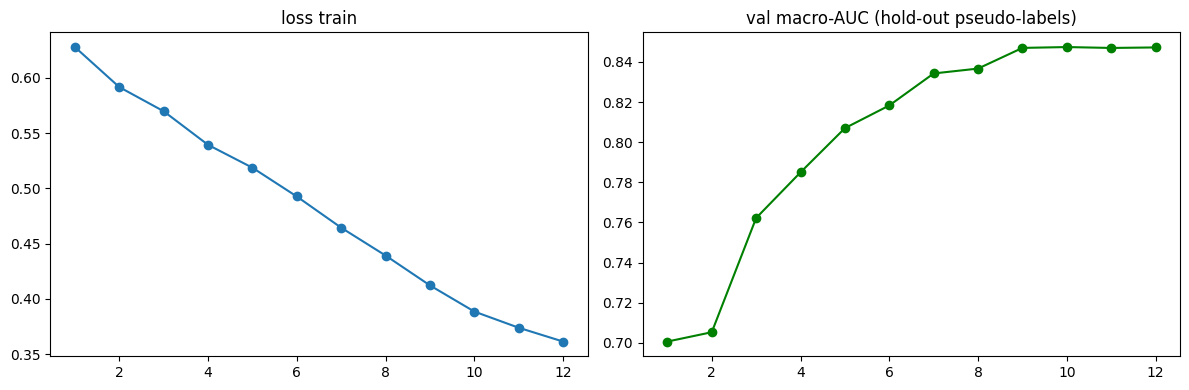

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(json.loads(hist_path.read_text()))
show = [c for c in ('epoch', 'loss', 'val_loss', 'val_macro_auc', 'gold_macro_auc') if c in hist.columns]
display(hist[show].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist.epoch, hist.loss, marker='o', label='train')
if 'val_loss' in hist.columns:
    axes[0].plot(hist.epoch, hist.val_loss, marker='o', label='val')
else:
    print('val_loss absent : relancer train.py pour la comparer a la train loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('BCE')
axes[0].set_title('loss train vs val')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist.epoch, hist.val_macro_auc, marker='o', label='val (pseudo-labels)')
if 'gold_macro_auc' in hist.columns:
    axes[1].plot(hist.epoch, hist.gold_macro_auc, marker='o', label='gold (58, pas de checkpoint)')
else:
    print('gold_macro_auc absent : relancer train.py pour la courbe gold vs val')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('macro-AUC')
axes[1].set_title('AUC val (labels appris) vs gold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0.45, 1.02)

plt.tight_layout()
plt.show()

In [3]:
# Sanity check gold du best.pt (58 etudes, jamais pour le checkpoint)
gold_path = run_dir / 'gold_sanity.json'
if gold_path.exists():
    gold = json.loads(gold_path.read_text())
    ep = gold.get('epoch', '?')
    print(f"macro-AUC gold (best.pt, epoch {ep}) :", round(gold['macro_auc'], 4))
    display(pd.Series(gold['per_target']).sort_values(ascending=False).round(3))
    if 'gold_macro_auc' in hist.columns:
        last = hist.iloc[-1]
        print('derniere epoch — val AUC :', round(last.val_macro_auc, 4),
              '| gold AUC :', round(last.gold_macro_auc, 4),
              '| ecart :', round(last.val_macro_auc - last.gold_macro_auc, 4))
else:
    print('pas de gold_sanity.json')

macro-AUC gold : 0.6701


Effusion            0.868
Synovitis           0.806
Baker's             0.774
Lateral Meniscus    0.746
PF OA               0.717
Lateral OA          0.635
Medial OA           0.619
ACL                 0.616
Contusion           0.603
MCL                 0.570
Medial Meniscus     0.544
Fracture            0.542
dtype: float64